# Day 2 — Logistic Regression + Gradient Descent
### ML Primer for bioinformatics & clinical systems biology

**Today's question:** can the cytokine panel tell **RA patients from healthy controls**?

The target is now **binary** (`ra_status` = 0/1), so this is **classification**.

**By the end of today you will be able to:**
1. Explain why linear regression is the wrong tool for a 0/1 outcome.
2. Interpret logistic regression coefficients as **odds ratios**.
3. Write **gradient descent** from scratch and understand learning rates.
4. Evaluate a classifier the way clinicians do: sensitivity, specificity, PPV/NPV, ROC/AUC, PR curves, calibration.
5. Spot **target leakage**, the most common way biomarker papers report a perfect AUC that never replicates.

## 0. Setup (same data preparation as Day 1)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             accuracy_score, brier_score_loss, confusion_matrix, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

DATA = Path("../data/biomarker-analyses/elisa_biomarker_analysis_qmd/data/elisa_biomarker_data.csv")
df = pd.read_csv(DATA)
CYTOKINES = ["TNF-alpha", "IL-1beta", "IL-6", "IL-8", "IL-10",
             "IL-17A", "IL-18", "IFN-gamma", "MCP-1", "VEGF"]

d = pd.DataFrame({
    "ra": df["ra_status"],
    "age": df["age"], "bmi": df["bmi"],
    "female": (df["gender"] == "F").astype(int), "smoking": df["smoking"],
    "disease_duration": df["disease_duration"],
    "rf_positive": df["rf_positive"], "anti_ccp_positive": df["anti_ccp_positive"],
    "log_crp": np.log2(df["crp_mg_l"]), "log_esr": np.log2(df["esr_mm_h"]),
})
for c in CYTOKINES:
    d["log_" + c.replace("-", "_")] = np.log2(df[c])
LOG_CYT = [c for c in d.columns if c.startswith("log_") and c not in ("log_crp", "log_esr")]
print(d["ra"].value_counts().rename({0: "control", 1: "RA"}).to_dict())

{'control': 60, 'RA': 40}


## 1. Why not just use linear regression?

We could code RA as 1 and controls as 0 and fit a straight line. That is the "linear probability model". The problem: a line doesn't know that a probability has to stay between 0 and 1.

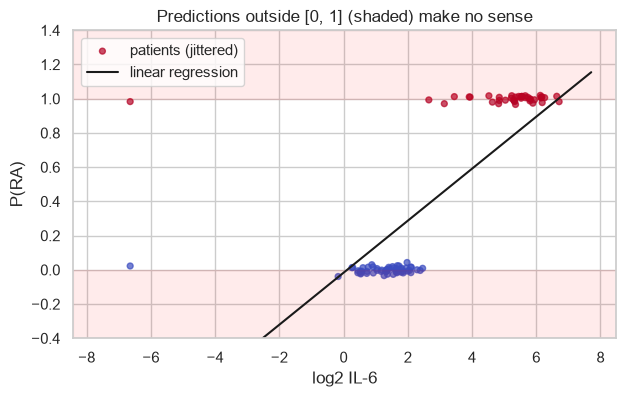

In [2]:
x = d["log_IL_6"]
lin = np.polyfit(x, d["ra"], 1)
xs = np.linspace(x.min() - 1, x.max() + 1, 300)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(x, d["ra"] + np.random.default_rng(SEED).normal(0, 0.02, len(d)), s=18, alpha=0.7,
           c=d["ra"], cmap="coolwarm", label="patients (jittered)")
ax.plot(xs, np.polyval(lin, xs), color="k", label="linear regression")
ax.axhspan(1, 1.5, color="red", alpha=0.08); ax.axhspan(-0.5, 0, color="red", alpha=0.08)
ax.set(ylim=(-0.4, 1.4), xlabel="log2 IL-6", ylabel="P(RA)", title="Predictions outside [0, 1] (shaded) make no sense")
ax.legend(loc="upper left");

## 2. The logistic model

Logistic regression keeps the linear part but passes it through the **sigmoid** (logistic) function, which squashes any number into (0, 1):

$$P(\text{RA}) = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = \beta_0 + \beta_1 x$$

Equivalently, the model is **linear on the log-odds scale**:

$$\log \frac{p}{1-p} = \beta_0 + \beta_1 x$$

So $e^{\beta_1}$ is the **odds ratio (OR)** for a one-unit increase in $x$. On our log2 scale, one unit means *a doubling of the cytokine concentration*.

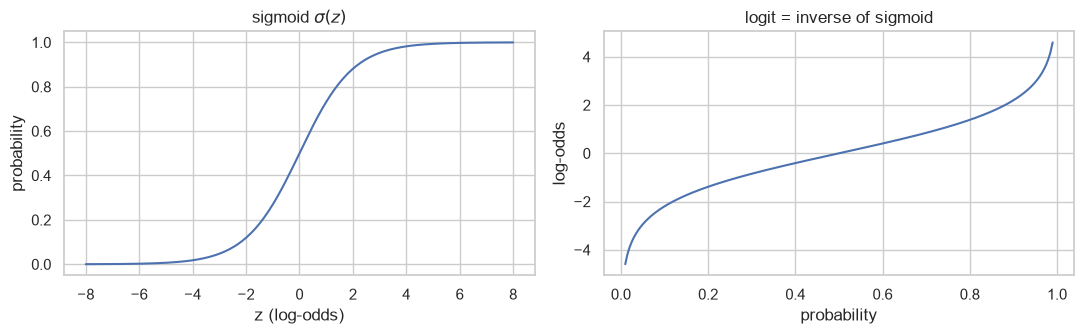

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(z, sigmoid(z)); axes[0].set(title=r"sigmoid $\sigma(z)$", xlabel="z (log-odds)", ylabel="probability")
p = np.linspace(0.01, 0.99, 200)
axes[1].plot(p, np.log(p / (1 - p))); axes[1].set(title="logit = inverse of sigmoid", xlabel="probability", ylabel="log-odds")
plt.tight_layout()

### Fit and interpret: RA ~ IL-6

In [4]:
m_il6 = smf.logit("ra ~ log_IL_6", data=d).fit(disp=0)
print(m_il6.summary().tables[1])

b0, b1 = m_il6.params
lo, hi = np.exp(m_il6.conf_int().loc["log_IL_6"])
print(f"\nOdds ratio per doubling of IL-6: {np.exp(b1):.2f} (95% CI {lo:.2f}–{hi:.2f})")
print(f"IL-6 concentration where P(RA) = 50%: 2^({-b0:.2f}/{b1:.2f}) = {2 ** (-b0 / b1):.1f} pg/mL")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.6878      0.805     -5.821      0.000      -6.266      -3.110
log_IL_6       1.4423      0.260      5.552      0.000       0.933       1.951

Odds ratio per doubling of IL-6: 4.23 (95% CI 2.54–7.04)
IL-6 concentration where P(RA) = 50%: 2^(4.69/1.44) = 9.5 pg/mL


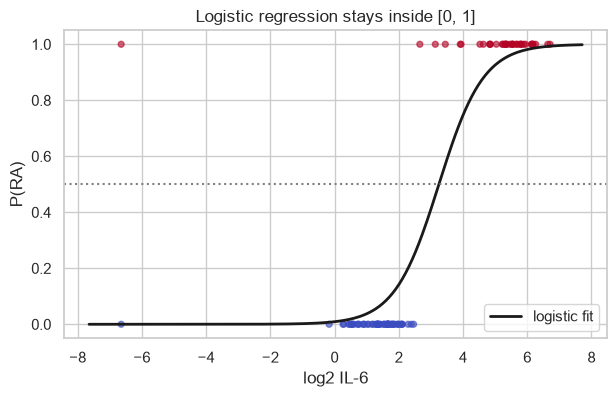

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(x, d["ra"], s=18, alpha=0.6, c=d["ra"], cmap="coolwarm")
ax.plot(xs, sigmoid(b0 + b1 * xs), color="k", lw=2, label="logistic fit")
ax.axhline(0.5, ls=":", color="grey")
ax.set(xlabel="log2 IL-6", ylabel="P(RA)", title="Logistic regression stays inside [0, 1]")
ax.legend();

> **Reality check:** an odds ratio this large and an AUC near 0.98 for a *single* cytokine would be extraordinary in a real RA cohort. This is mock data with strong built-in group differences. Real biomarkers typically give AUCs of 0.6–0.8, and all the evaluation tools below matter even more then.

## 3. The loss function: log-loss

In linear regression we minimised squared residuals. For probabilities we use the **log-loss** (binary cross-entropy), the negative log-likelihood of a Bernoulli outcome:

$$L(\beta) = -\frac{1}{n}\sum_i \Big[ y_i \log p_i + (1-y_i)\log(1-p_i) \Big]$$

Intuition: a confident wrong prediction is punished heavily.

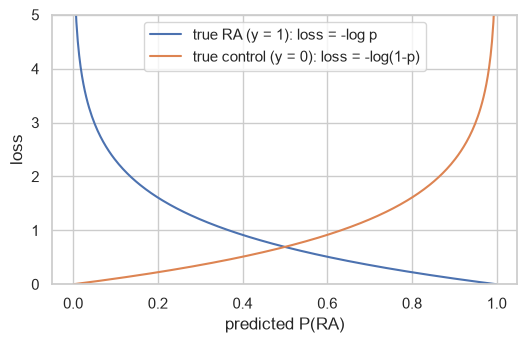

In [6]:
p = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(6, 3.5))
plt.plot(p, -np.log(p), label="true RA (y = 1): loss = -log p")
plt.plot(p, -np.log(1 - p), label="true control (y = 0): loss = -log(1-p)")
plt.xlabel("predicted P(RA)"); plt.ylabel("loss"); plt.ylim(0, 5); plt.legend();

Unlike least squares, **there is no closed-form solution** for the β that minimise log-loss. We have to search for them, and the workhorse for that is **gradient descent**.

## 4. Gradient descent from scratch

The idea: stand somewhere on the loss surface, find the direction of steepest *descent* (the negative gradient), take a small step and repeat.

$$\beta \leftarrow \beta - \eta \, \nabla L(\beta)$$

For logistic regression the gradient is pleasingly simple:

$$\nabla L = \frac{1}{n} X^\top (p - y)$$

(prediction error, weighted by the features). $\eta$ is the **learning rate**, i.e. the step size.

We **standardise** *x* first. Gradient descent converges much faster when features are on similar scales, and this is why ML pipelines scale features almost by default.

In [7]:
xz = ((x - x.mean()) / x.std()).to_numpy()
X = np.column_stack([np.ones_like(xz), xz])      # column of 1s for the intercept
yv = d["ra"].to_numpy()

def log_loss(beta, X=X, y=yv):
    p = np.clip(sigmoid(X @ beta), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradient(beta, X=X, y=yv):
    return X.T @ (sigmoid(X @ beta) - y) / len(y)

def gradient_descent(lr, n_steps=200, start=(-2.0, -1.0)):
    beta = np.array(start, dtype=float)
    path = [beta.copy()]
    for _ in range(n_steps):
        beta -= lr * gradient(beta)
        path.append(beta.copy())
    return np.array(path)

path = gradient_descent(lr=1.0)
print("gradient descent  β =", path[-1].round(3), " loss =", round(log_loss(path[-1]), 4))

# Check against statsmodels on the same standardised feature
ref = smf.logit("ra ~ xz", data=pd.DataFrame({"ra": yv, "xz": xz})).fit(disp=0).params.to_numpy()
print("statsmodels       β =", ref.round(3), " loss =", round(log_loss(ref), 4))

gradient descent  β = [-0.731  3.536]  loss = 0.2389
statsmodels       β = [-0.731  3.545]  loss = 0.2389


### Watching it walk downhill

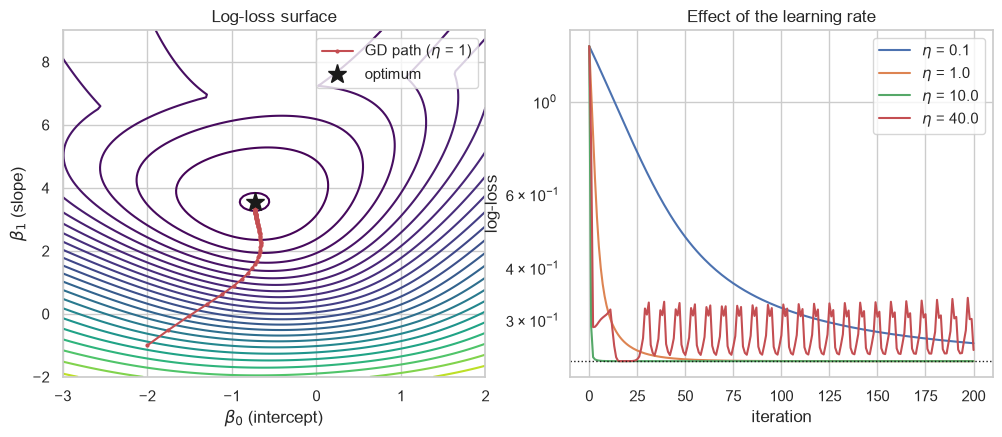

In [8]:
b0g, b1g = np.meshgrid(np.linspace(-3, 2, 120), np.linspace(-2, 9, 120))
Z = np.array([log_loss(np.array([a, b])) for a, b in zip(b0g.ravel(), b1g.ravel())]).reshape(b0g.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cs = axes[0].contour(b0g, b1g, Z, levels=np.geomspace(Z.min() + 1e-3, Z.max(), 25), cmap="viridis")
axes[0].plot(*path.T, "o-", ms=2, color="C3", label=r"GD path ($\eta$ = 1)")
axes[0].plot(*ref, "k*", ms=14, label="optimum")
axes[0].set(xlabel=r"$\beta_0$ (intercept)", ylabel=r"$\beta_1$ (slope)", title="Log-loss surface")
axes[0].legend()

for lr in [0.1, 1.0, 10.0, 40.0]:
    losses = [log_loss(b) for b in gradient_descent(lr)]
    axes[1].plot(losses, label=rf"$\eta$ = {lr}")
axes[1].axhline(log_loss(ref), color="k", ls=":", lw=1)
axes[1].set(xlabel="iteration", ylabel="log-loss", title="Effect of the learning rate", yscale="log")
axes[1].legend();

- **η too small** → correct but painfully slow.
- **η about right** → converges in a few dozen steps.
- **η too large** → overshoots and zig-zags, or even diverges.

Everything you'll hear about in deep learning (SGD, mini-batches, Adam, learning-rate schedules) is a refinement of this loop. In practice scikit-learn uses smarter second-order solvers (L-BFGS) for logistic regression, but the principle is the same.

## 5. A multi-marker classifier, evaluated honestly

Now use all 10 cytokines plus age, sex, BMI and smoking. As on Day 1: **stratified train/test split**, with scaling inside a pipeline.

We compare it to the **one-marker** model. More features are not automatically better.

In [9]:
train, test = train_test_split(d, test_size=0.3, random_state=SEED, stratify=d["ra"])
PANEL = LOG_CYT + ["age", "female", "bmi", "smoking"]

def fit_clf(features, C=np.inf):            # C = inverse penalty strength; np.inf = unpenalised
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=10_000))
    return clf.fit(train[features], train["ra"])

models = {"IL-6 only": ["log_IL_6"], "14-feature panel": PANEL}
fitted = {name: fit_clf(f) for name, f in models.items()}
for name, clf in fitted.items():
    f = models[name]
    print(f"{name:18s} train AUC = {roc_auc_score(train['ra'], clf.predict_proba(train[f])[:, 1]):.3f} | "
          f"test AUC = {roc_auc_score(test['ra'], clf.predict_proba(test[f])[:, 1]):.3f}")

IL-6 only          train AUC = 0.964 | test AUC = 1.000
14-feature panel   train AUC = 1.000 | test AUC = 0.958


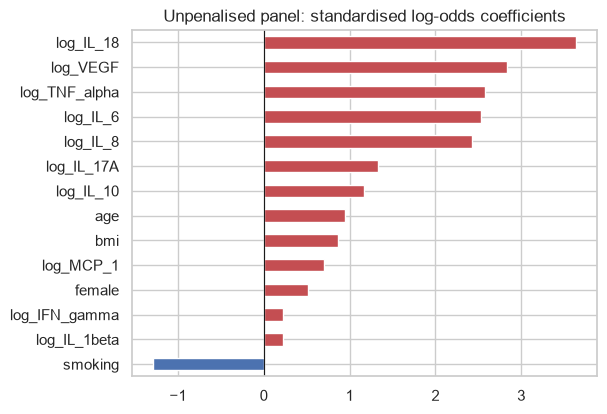

In [10]:
coefs = pd.Series(fitted["14-feature panel"][-1].coef_[0], index=PANEL).sort_values()
coefs.plot.barh(figsize=(6, 4.5), color=np.where(coefs > 0, "C3", "C0"),
                title="Unpenalised panel: standardised log-odds coefficients")
plt.axvline(0, color="k", lw=0.8);

The panel fits the training data perfectly (train AUC = 1). Its coefficients are large and partly implausible, e.g. signs you would not expect biologically. This is **(quasi-)complete separation**: when the classes can be split perfectly, the likelihood keeps improving as coefficients grow towards ±∞. Unpenalised logistic regression has no finite optimum. It is the classification version of Day 1's *p ≫ n* problem, and regularisation (Day 3) is again the cure.

## 6. Evaluation metrics clinicians ask for

### 6.1 Confusion matrix at a threshold

A classifier outputs a **probability**. To make a decision we pick a **threshold** (0.5 by default).

sensitivity (recall, TPR)    0.917
specificity (TNR)            1.000
PPV (precision)              1.000
NPV                          0.947
accuracy                     0.967
dtype: float64

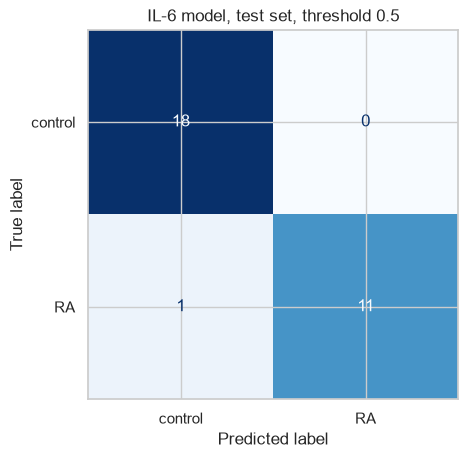

In [11]:
clf, feats = fitted["IL-6 only"], models["IL-6 only"]
p_test = clf.predict_proba(test[feats])[:, 1]

def clinical_metrics(y, p, threshold=0.5):
    tn, fp, fn, tp = confusion_matrix(y, p >= threshold).ravel()
    return pd.Series({
        "sensitivity (recall, TPR)": tp / (tp + fn),
        "specificity (TNR)":         tn / (tn + fp),
        "PPV (precision)":           tp / (tp + fp) if tp + fp else np.nan,
        "NPV":                       tn / (tn + fn) if tn + fn else np.nan,
        "accuracy":                  (tp + tn) / len(y),
    })

ConfusionMatrixDisplay.from_predictions(test["ra"], p_test >= 0.5, display_labels=["control", "RA"],
                                        cmap="Blues", colorbar=False)
plt.title("IL-6 model, test set, threshold 0.5")
clinical_metrics(test["ra"], p_test).round(3)

| Metric | Question it answers |
|---|---|
| **Sensitivity** | Of the patients *with* RA, what fraction do we catch? |
| **Specificity** | Of the healthy people, what fraction do we correctly clear? |
| **PPV** | If the test says RA, how likely is it true? *Depends on prevalence!* |
| **NPV** | If the test says healthy, how likely is that true? |
| **Accuracy** | Overall fraction correct. *Misleading under class imbalance.* |

**Accuracy trap:** with 60% controls, a "model" that always says *control* is 60% accurate. With 1% prevalence (population screening) it would be 99% accurate and completely useless. Always compare against this **no-information baseline**.

In [12]:
print(f"Always-'control' baseline accuracy on the test set: {accuracy_score(test['ra'], np.zeros(len(test))):.0%}")

Always-'control' baseline accuracy on the test set: 60%


### 6.2 ROC curve and AUC: all thresholds at once

The ROC curve plots sensitivity against 1 − specificity as the threshold moves from 1 to 0. **AUC** is the probability that a randomly chosen RA patient gets a higher score than a randomly chosen control. 0.5 is a coin flip and 1.0 is perfect.

**The test set has only 30 patients (12 RA)**, so one split is noisy (remember Day 1, Exercise 2). For more stable curves we use **out-of-fold predictions**: 5-fold cross-validation, where every patient is predicted by a model that never saw them. (Day 3 covers CV properly.)

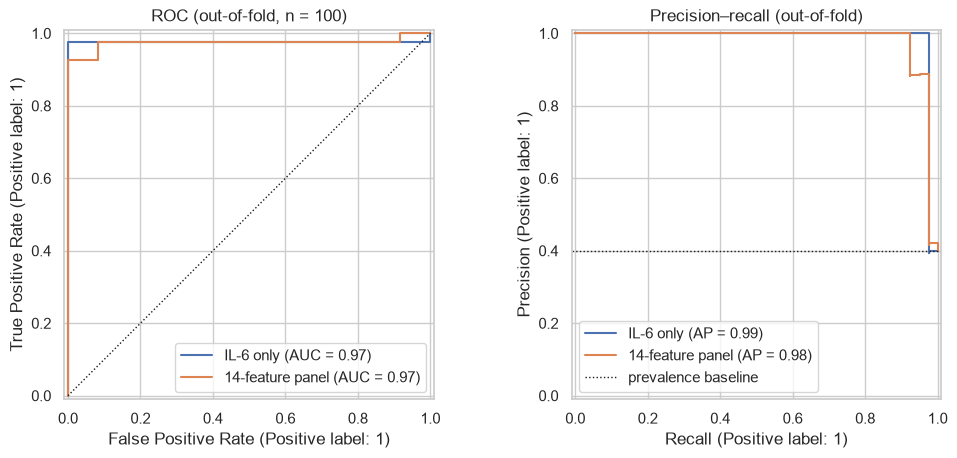

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {}
for name, f in models.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=10_000))
    oof[name] = cross_val_predict(clf, d[f], d["ra"], cv=cv, method="predict_proba")[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for name, p in oof.items():
    RocCurveDisplay.from_predictions(d["ra"], p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(d["ra"], p, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_title("ROC (out-of-fold, n = 100)")
axes[1].axhline(d["ra"].mean(), color="k", ls=":", lw=1, label="prevalence baseline")
axes[1].set_title("Precision–recall (out-of-fold)"); axes[1].legend(loc="lower left");

The **PR curve** is more informative than ROC when positives are rare (e.g. 2% of a screening population). Its baseline is the prevalence, not 0.5.

### 6.3 Choosing a threshold for the clinical use case

0.5 is arbitrary. The right threshold depends on the **cost of errors**:
- **Rule-out / screening test:** we can't afford to miss RA → we want high sensitivity and accept more false positives.
- **Confirmatory test before an expensive or toxic treatment:** we want high specificity.

In [14]:
p = oof["IL-6 only"]
rows = [clinical_metrics(d["ra"], p, t).rename(t) for t in [0.1, 0.25, 0.5, 0.75, 0.9]]
pd.DataFrame(rows).rename_axis("threshold").round(2)

,"sensitivity (recall, TPR)",specificity (TNR),PPV (precision),NPV,accuracy
threshold,,,,,
0.10,0.98,0.67,0.66,0.98,0.79
0.25,0.98,1.00,1.00,0.98,0.99
0.50,0.92,1.00,1.00,0.95,0.97
0.75,0.85,1.00,1.00,0.91,0.94
0.90,0.75,1.00,1.00,0.86,0.90


### 6.4 Calibration: can we trust the probabilities?

AUC only measures **ranking**. When a model says "70% chance of RA", do about 70% of such patients actually have RA? That is **calibration**, and it matters whenever probabilities are shown to clinicians or used for risk stratification. The **Brier score** (mean squared error of the probabilities) combines discrimination and calibration; lower is better.

IL-6 only          Brier = 0.028   AUC = 0.975
14-feature panel   Brier = 0.034   AUC = 0.973


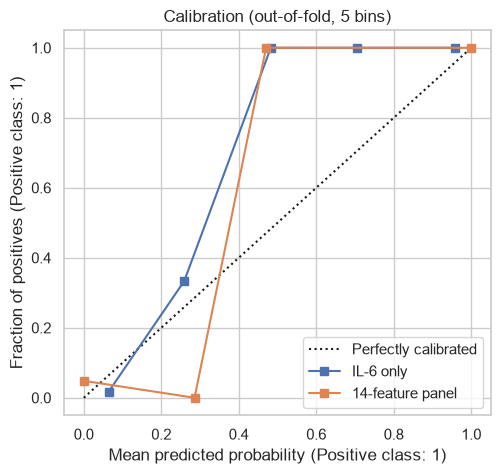

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in oof.items():
    CalibrationDisplay.from_predictions(d["ra"], p, n_bins=5, name=name, ax=ax)
    print(f"{name:18s} Brier = {brier_score_loss(d['ra'], p):.3f}   AUC = {roc_auc_score(d['ra'], p):.3f}")
ax.set_title("Calibration (out-of-fold, 5 bins)");

Overfit, unpenalised models tend to produce **overconfident** probabilities (pushed towards 0 and 1). With n = 100 calibration curves are rough, so treat them as a sanity check rather than proof.

## 7. 🚨 Target leakage: the perfect AUC that never replicates

The table also has clinical variables: disease duration, RF and anti-CCP serology, and ESR. How well does each one "predict" RA on its own?

In [16]:
for leaky in [["disease_duration"], ["rf_positive", "anti_ccp_positive"], ["log_esr"]]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10_000))
    p_leaky = cross_val_predict(clf, d[leaky], d["ra"], cv=cv, method="predict_proba")[:, 1]
    print(f"out-of-fold AUC using {' + '.join(leaky):35s} {roc_auc_score(d['ra'], p_leaky):.3f}")
print()
print(pd.crosstab(d["ra"].map({0: "control", 1: "RA"}), d["disease_duration"] > 0,
                  colnames=["disease_duration > 0"]))

out-of-fold AUC using disease_duration                    1.000
out-of-fold AUC using rf_positive + anti_ccp_positive     0.982
out-of-fold AUC using log_esr                             0.985

disease_duration > 0  False  True 
ra                                
RA                        0     40
control                  60      0


`disease_duration` alone gives a **perfect AUC** without any biomarker. It is meaningless:
- `disease_duration` is **0 for every control by construction**. It literally encodes the answer.
- RF and anti-CCP are part of the **ACR/EULAR classification criteria** for RA. The diagnosis was partly *made* from them.
- ESR/CRP were probably measured *because* the patient was already suspected of having RA.

**Leakage = using information that wouldn't be available at prediction time, or that is a consequence of the outcome.** Ask of every feature: *"Would I have this value, measured this way, for a new undiagnosed patient at the moment I need the prediction?"* Other common forms in omics and clinical work:
- samples processed in **disease-specific batches** (the model learns the batch, not the biology),
- **feature selection on the full dataset** before cross-validation,
- the **same patient** (repeat visits, technical replicates) in both train and test.

## 8. Exercises

**Exercise 1: Prevalence changes PPV.** At threshold 0.5 the IL-6 model made **zero false positives among 60 controls**. Does that prove 100% specificity? No. By the **rule of three**, observing 0 events in *n* trials gives an approximate 95% upper bound of 3/*n* on the true rate, so specificity could plausibly be as low as 1 − 3/60 = 0.95.

Using the out-of-fold sensitivity and this conservative specificity of 0.95, compute the PPV for (a) a rheumatology referral population with 40% prevalence and (b) general population screening with 1% prevalence. Use Bayes' rule:
$\text{PPV} = \frac{\text{sens}\cdot\pi}{\text{sens}\cdot\pi + (1-\text{spec})(1-\pi)}$.

In [17]:
# your code here

In [18]:
# Solution 1
m = clinical_metrics(d["ra"], oof["IL-6 only"], 0.5)
sens = m["sensitivity (recall, TPR)"]
n_controls = (d["ra"] == 0).sum()
print(f"observed specificity = {m['specificity (TNR)']:.2f} on only {n_controls} controls")
spec = 1 - 3 / n_controls                      # rule-of-three conservative estimate
for prev in [0.40, 0.01]:
    ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev))
    print(f"prevalence {prev:>4.0%}: sens = {sens:.2f}, spec = {spec:.2f} -> PPV = {ppv:.0%}")
# The same test is far less useful for screening: most positives would be false positives.
# Small validation cohorts cannot establish the very high specificity that screening needs.

observed specificity = 1.00 on only 60 controls
prevalence  40%: sens = 0.93, spec = 0.95 -> PPV = 92%
prevalence   1%: sens = 0.93, spec = 0.95 -> PPV = 16%


**Exercise 2: Pick a rule-out threshold.** Find the highest threshold on the IL-6 out-of-fold probabilities that still gives **sensitivity ≥ 95%**. What specificity do you get? (Hint: `sklearn.metrics.roc_curve` returns `fpr, tpr, thresholds`.)

In [19]:
# your code here

In [20]:
# Solution 2
from sklearn.metrics import roc_curve

fpr, tpr, thr = roc_curve(d["ra"], oof["IL-6 only"])
i = np.argmax(tpr >= 0.95)   # first (= highest) threshold reaching 95% sensitivity
print(f"threshold = {thr[i]:.3f} -> sensitivity = {tpr[i]:.2f}, specificity = {1 - fpr[i]:.2f}")
# In a real study, choose this threshold on training/CV data and confirm it on an independent cohort.

threshold = 0.293 -> sensitivity = 0.97, specificity = 1.00


**Exercise 3: Your own gradient descent with more features.** Reuse `log_loss`, `gradient` and the update rule to fit logistic regression on three standardised features (`log_IL_6`, `log_TNF_alpha`, `age`). Compare your coefficients with `LogisticRegression(C=np.inf)` (no penalty).

In [21]:
# your code here

In [22]:
# Solution 3
feats3 = ["log_IL_6", "log_TNF_alpha", "age"]
Z3 = StandardScaler().fit_transform(d[feats3])
X3 = np.column_stack([np.ones(len(d)), Z3])
beta = np.zeros(X3.shape[1])
for _ in range(5000):
    beta -= 1.0 * gradient(beta, X3, yv)
sk = LogisticRegression(C=np.inf, max_iter=10_000).fit(Z3, yv)
print(pd.DataFrame({"gradient descent": beta, "sklearn": np.r_[sk.intercept_, sk.coef_[0]]},
                   index=["intercept"] + feats3).round(3))

               gradient descent  sklearn
intercept                -0.654   -0.654
log_IL_6                  3.197    3.196
log_TNF_alpha             0.686    0.686
age                       0.368    0.368


## Summary

| Concept | Takeaway |
|---|---|
| Logistic regression | Linear in log-odds; $e^{\beta}$ = odds ratio (per doubling on the log2 scale) |
| Log-loss | Punishes confident mistakes; has no closed-form minimum |
| Gradient descent | Step against the gradient; the learning rate controls speed vs stability; scale your features |
| Separation | Perfectly separable data → unpenalised coefficients blow up → regularise |
| Metrics | Sensitivity/specificity are properties of the test; PPV/NPV depend on prevalence |
| ROC/AUC vs PR | AUC measures ranking; use PR curves when positives are rare |
| Calibration | Are the probabilities themselves trustworthy? Check them with calibration plots and the Brier score |
| Leakage | If a feature wouldn't exist for a new undiagnosed patient, it doesn't belong in the model |

**Next — Day 3: Model Performance + Regularisation.** Cross-validation done properly (nested CV, grouped CV by patient/batch), and LASSO / ridge / elastic net for biomarker selection in the p ≫ n regime. We'll move to the **aging proteomics dataset** (≈2,500 proteins, 23 samples).